In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# === 1. Parameters ===
tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]
equal_weight = 1 / len(tickers)

In [3]:
# === 2. Download Adjusted Close Data ===
data = yf.download(tickers, period="10y", interval="1wk", auto_adjust=False)["Adj Close"]
data = data.dropna()  # Drop rows with missing data

[*********************100%***********************]  7 of 7 completed


In [4]:
# === 3. Normalize prices (so week 0 = 1) ===
normalized = data / data.iloc[0]

In [5]:
# === 4. BAH (Buy-And-Hold) Portfolio ===
# Fixed allocation from t=0 (just scales each column by 1/7 and sums)
V0 = 10_000
bah_portfolio = (normalized * equal_weight).sum(axis=1) * V0

In [6]:
# === 5. Constantly Rebalanced Portfolio ===
# Compute weekly returns
weekly_returns = data.pct_change().dropna()
# Initialise list of rebalanced portfolio values
rebalanced_values = [10_000]  # <- Start at 10,000

# Rebalance to equal weights weekly
for returns in weekly_returns.itertuples(index=False):
    portfolio_value = rebalanced_values[-1]
    step_growth = sum(equal_weight * r for r in returns)
    rebalanced_values.append(portfolio_value * (1 + step_growth))

rebalanced_portfolio = pd.Series(rebalanced_values, index = data.index)

In [7]:
# === 6. Create Series of Updated Theta Values ===
theta = normalized.shift(1).div(normalized.shift(1).sum(axis=1), axis=0)
# .shift(1) will create a first row of NaN values but this is fine, can be excluded later for visualisation purposes

In [9]:
# === 7. Constantly Rebalanced Portfolio with Transaction Costs using Theta Values ===

transaction_costs = [0]
rebalanced_values = [10_000]

# Loop starts at 1 because theta is shifted by 1
for t in range(1, len(data)):
    V_t_minus_1 = rebalanced_values[-1]
    
    # Price ratio for each stock: Xᵢ(t) / Xᵢ(t-1)
    price_ratio = data.iloc[t] / data.iloc[t - 1]

    # θᵢₜ = equal weights for rebalancing
    theta_t = np.array([equal_weight] * len(tickers))
    #theta_t = theta.iloc[t]

    # θᵢₜ₋₁ from the precomputed Series (weights from previous time)
    theta_t_minus_1 = theta.iloc[t]

    # Δᵢₜ = θᵢₜ * Vₜ - θᵢₜ₋₁ * Vₜ₋₁ * (Xᵢ(t) / Xᵢ(t-1))
    capital_now = theta_t * V_t_minus_1
    capital_prev = theta_t_minus_1 * V_t_minus_1 * price_ratio.values
    delta = capital_now - capital_prev

    # Apply transaction cost formula
    cost = sum(max(0.001 * abs(d), 1) for d in delta if abs(d) > 0)

    # Apply returns after subtracting transaction costs
    step_return = weekly_returns.iloc[t - 1]
    growth = sum(theta_t * step_return)
    V_t = (V_t_minus_1 - cost) * (1 + growth)

    transaction_costs.append(transaction_costs[-1] + cost)
    rebalanced_values.append(V_t)

rebalanced_portfolio_net = pd.Series(rebalanced_values, index=data.index[:len(rebalanced_values)])
transaction_cost_series = pd.Series(transaction_costs, index=data.index[:len(transaction_costs)])

In [10]:
# === 8. Momentum + Anti-Momentum Strategy ===
lookback = 52  # weekly, roughly 1 year

# Rolling max and min
rolling_max = data.rolling(window=lookback, min_periods=lookback).max()
rolling_min = data.rolling(window=lookback, min_periods=lookback).min()

# Momentum weights
momentum_weights = (data - rolling_min) / (rolling_max - rolling_min)
anti_momentum_weights = (rolling_max - data) / (rolling_max - rolling_min)

# Avoid divide-by-zero
#momentum_weights = momentum_weights.replace([np.inf, -np.inf], np.nan).fillna(0)
#anti_momentum_weights = anti_momentum_weights.replace([np.inf, -np.inf], np.nan).fillna(0)

# Normalize weights to sum to 1 - this causes problems!
#momentum_weights = momentum_weights.div(momentum_weights.sum(axis=1), axis=0)
#anti_momentum_weights = anti_momentum_weights.div(anti_momentum_weights.sum(axis=1), axis=0)

# Create separate momentum and anti-momentum strategies

momentum_values = [V0]
anti_momentum_values = [V0]
for t in range(1, len(data)):
    if t < lookback:
        # Not enough lookback yet — hold value constant
        momentum_values.append(momentum_values[-1])
        anti_momentum_values.append(anti_momentum_values[-1])
        continue

    weights1 = momentum_weights.iloc[t - 1].values  # use previous period's weights for momentum portfolio
    weights2 = anti_momentum_weights.iloc[t - 1].values  # use previous period's weights for anti-momentum portfolio
    step_return = weekly_returns.iloc[t - 1].values
    growth1 = np.dot(weights1, step_return)
    growth2 = np.dot(weights2, step_return)
    V_t1 = momentum_values[-1] * (1 + growth1)
    V_t2 = anti_momentum_values[-1] * (1 + growth2)
    anti_momentum_values.append(V_t1)
    momentum_values.append(V_t2)

momentum_portfolio = pd.Series(momentum_values, index=data.index[:len(momentum_values)])
anti_momentum_portfolio = pd.Series(anti_momentum_values, index=data.index[:len(anti_momentum_values)])

#Compute each stratefy's return series
momentum_returns = momentum_portfolio.pct_change().dropna()
antimomentum_returns = anti_momentum_portfolio.pct_change().dropna()

# Correlate momentum and anti-momentum portfolios
correlation = momentum_returns.corr(antimomentum_returns)
overall_corr = correlation.mean()  # Average across assets (or use total portfolio)
#print(momentum_returns.to_string())
print(overall_corr)

-0.35769598758974874


In [11]:
#print(len(momentum_values))
#print(len(momentum_portfolio))
#print(len(rebalanced_portfolio_net))
#print(len(bah_portfolio))
print(momentum_portfolio)

Date
2015-07-13    1.000000e+04
2015-07-20    1.000000e+04
2015-07-27    1.000000e+04
2015-08-03    1.000000e+04
2015-08-10    1.000000e+04
                  ...     
2025-06-09    2.827938e+05
2025-06-16    1.098304e+07
2025-06-23    3.048570e+05
2025-06-30    1.436462e+07
2025-07-07    3.021967e+05
Length: 522, dtype: float64


In [12]:
# === 9. Market Index ===
market_index = (data.sum(axis=1) / data.sum(axis=1).iloc[0]) * V0
print(market_index.head())

Date
2015-07-13    10000.000000
2015-07-20     9987.245915
2015-07-27     9885.960129
2015-08-03     9769.741609
2015-08-10     9865.080993
dtype: float64


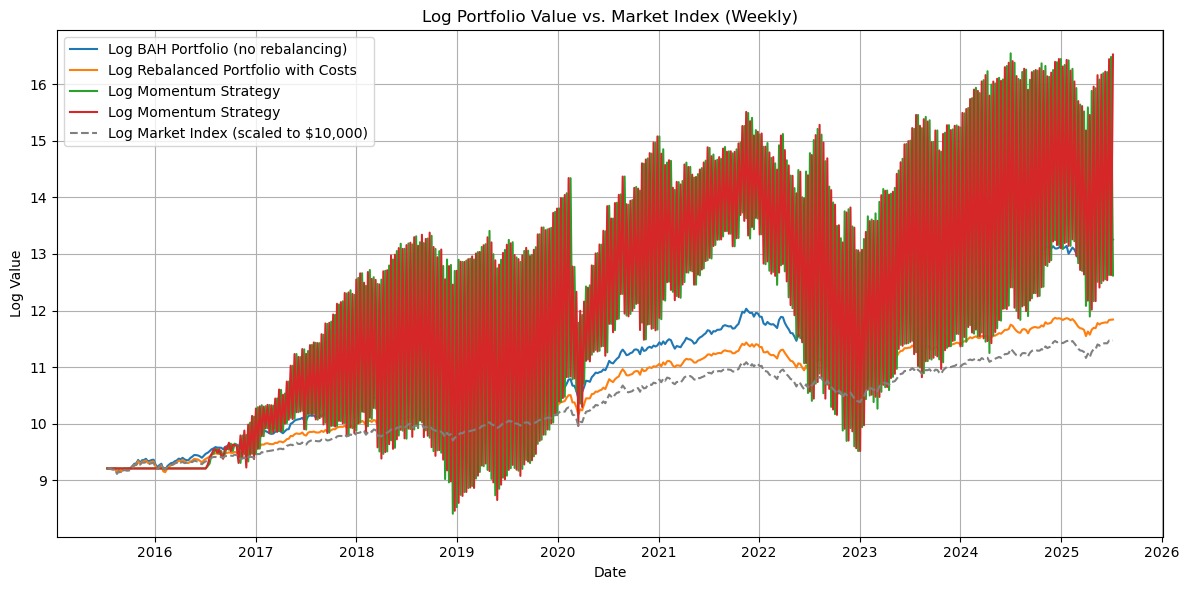

In [17]:
# === 10. Plot all three log values ===
plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(np.log(momentum_portfolio), label="Log Momentum Strategy")
plt.plot(np.log(anti_momentum_portfolio), label="Log Momentum Strategy")
plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)", linestyle="--", color="gray")
plt.title("Log Portfolio Value vs. Market Index (Weekly)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

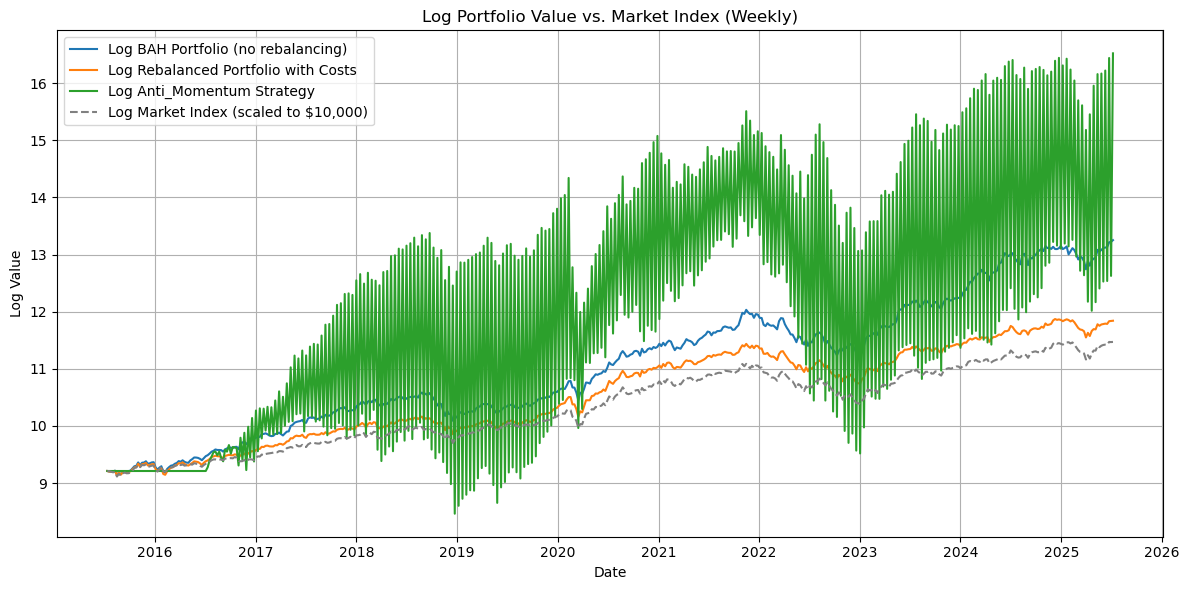

In [16]:
# === 11. Plot all three log values ===
plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(np.log(anti_momentum_portfolio), label="Log Anti_Momentum Strategy")
#plt.plot(np.log(momentum_portfolio), label="Log Momentum Strategy")
plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)", linestyle="--", color="gray")
plt.title("Log Portfolio Value vs. Market Index (Weekly)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

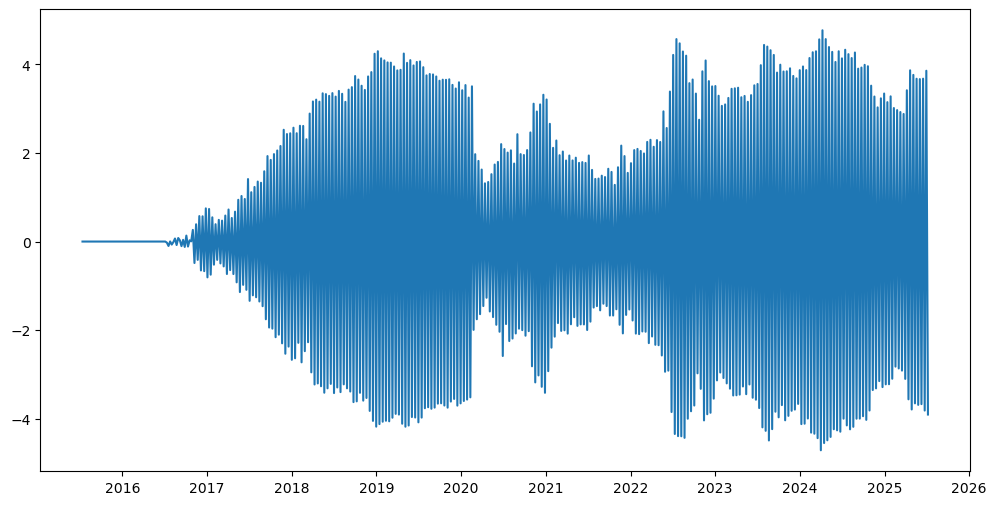

In [20]:
diff = np.log(momentum_portfolio) - np.log(anti_momentum_portfolio)
plt.figure(figsize=(12, 6))
#plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
#plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(diff, label="Momentum - Anti-Momentum (Log)")
#plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)", linestyle="--", color="gray")
#plt.title("Log Portfolio Value vs. Market Index (Weekly)")
#plt.xlabel("Date")
#plt.ylabel("Log Value")
#plt.legend()
#plt.grid(True)
#plt.tight_layout()
plt.show()

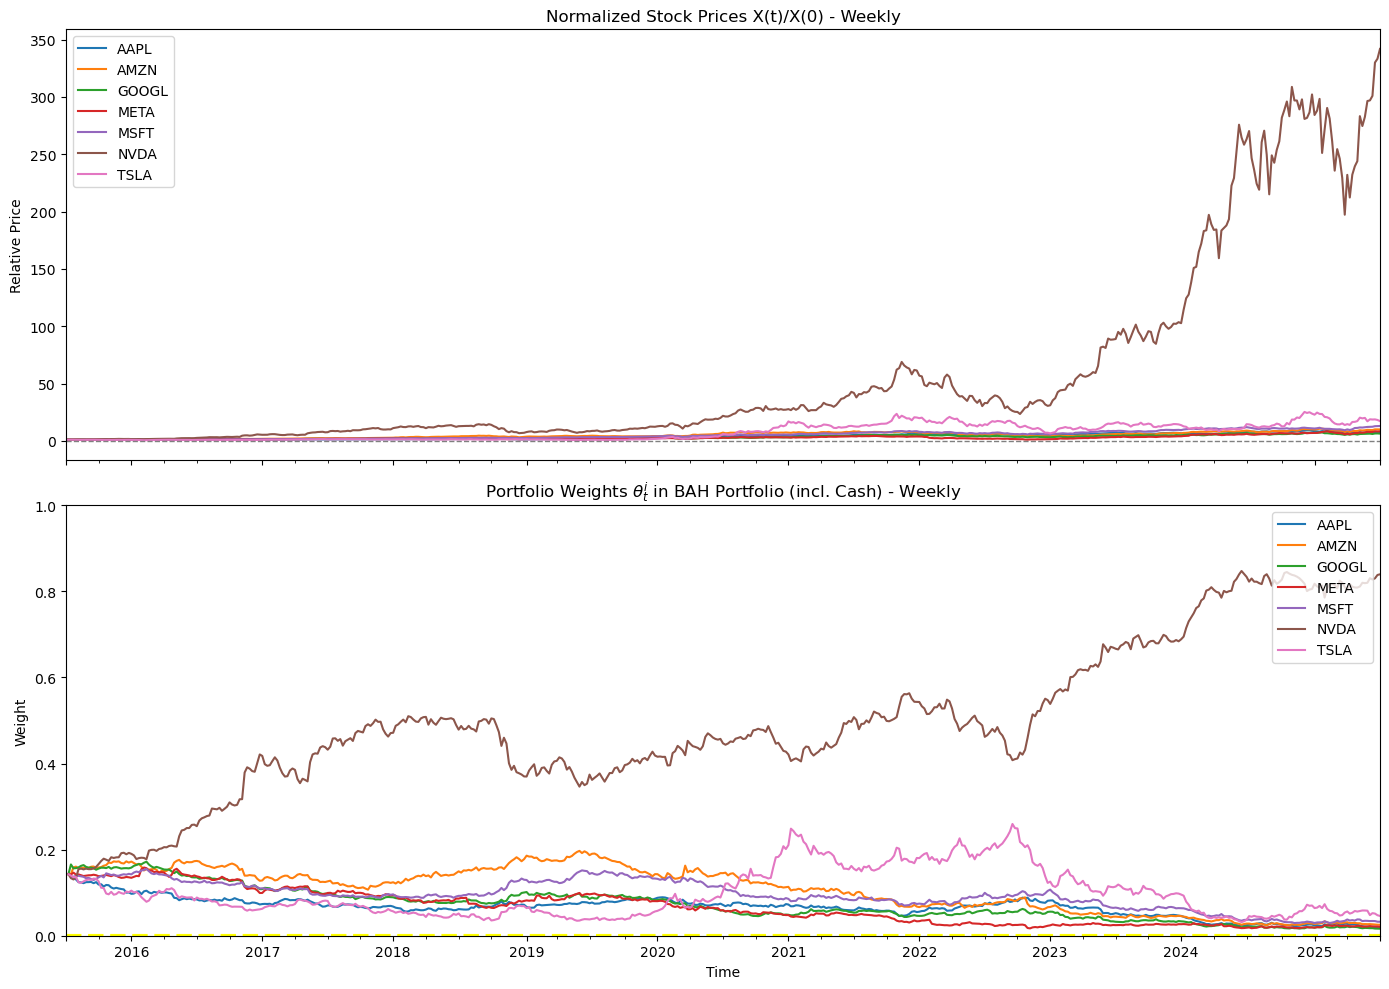

In [14]:
# === 11. Plot of theta time series against individual stock prices ===

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top plot: normalized stock prices
normalized.plot(ax=ax1)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)  
ax1.set_title("Normalized Stock Prices X(t)/X(0) - Weekly")
ax1.set_ylabel("Relative Price")
ax1.legend(loc="upper left")

# Bottom plot: theta values + cash position
theta.plot(ax=ax2)
ax2.axhline(0, color='yellow', linestyle='--', linewidth=3)  
ax2.set_title(r"Portfolio Weights $\theta_{t}^i$ in BAH Portfolio (incl. Cash) - Weekly")
ax2.set_ylabel("Weight")
ax2.set_ylim(0, 1)
ax2.legend(loc="upper right")
ax2.set_xlabel("Time")

plt.tight_layout()
plt.show()


In [15]:
# === 12. Compute MDD (maximal drawdown)
def compute_max_drawdown(series):
    running_max = series.cummax()
    drawdown = (series - running_max) / running_max
    max_drawdown = drawdown.min()
    return max_drawdown

In [16]:
# === 13. Compute MDD of each portfolio
mdd_bah = compute_max_drawdown(bah_portfolio)
mdd_rebalanced = compute_max_drawdown(rebalanced_portfolio_net)
mdd_momentum = compute_max_drawdown(momentum_portfolio)
mdd_market = compute_max_drawdown(market_index)

In [17]:
print(f"Max Drawdown (BAH):        {mdd_bah:.2%}")
print(f"Max Drawdown (Rebalanced): {mdd_rebalanced:.2%}")
print(f"Max Drawdown (Momentum):   {mdd_momentum:.2%}")
print(f"Max Drawdown (Market):     {mdd_market:.2%}")

Max Drawdown (BAH):        -54.54%
Max Drawdown (Rebalanced): -50.03%
Max Drawdown (Momentum):   -94.43%
Max Drawdown (Market):     -50.64%


In [18]:
help(theta)

Help on DataFrame in module pandas.core.frame object:

class DataFrame(pandas.core.generic.NDFrame, pandas.core.arraylike.OpsMixin)
 |  DataFrame(data=None, index: 'Axes | None' = None, columns: 'Axes | None' = None, dtype: 'Dtype | None' = None, copy: 'bool | None' = None) -> 'None'
 |  
 |  Two-dimensional, size-mutable, potentially heterogeneous tabular data.
 |  
 |  Data structure also contains labeled axes (rows and columns).
 |  Arithmetic operations align on both row and column labels. Can be
 |  thought of as a dict-like container for Series objects. The primary
 |  pandas data structure.
 |  
 |  Parameters
 |  ----------
 |  data : ndarray (structured or homogeneous), Iterable, dict, or DataFrame
 |      Dict can contain Series, arrays, constants, dataclass or list-like objects. If
 |      data is a dict, column order follows insertion-order. If a dict contains Series
 |      which have an index defined, it is aligned by its index. This alignment also
 |      occurs if data 

In [17]:
theta.head()

Ticker,AAPL,AMZN,GOOGL,META,MSFT,NVDA,TSLA
Date,,,,,,,
2015-06-29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-07-06,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857,0.142857
2015-07-13,0.141117,0.146652,0.147053,0.145828,0.145418,0.139985,0.133947
2015-07-20,0.136531,0.146965,0.170235,0.144899,0.139840,0.130899,0.130632
2015-07-27,0.132441,0.162687,0.160905,0.149390,0.139170,0.127918,0.127487
